In [1]:
%pip install pillow


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: /home/linuxbrew/.linuxbrew/Cellar/jupyterlab/4.3.3/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### imports

In [72]:
import numpy as np 
from PIL import Image
import matplotlib

### murchik

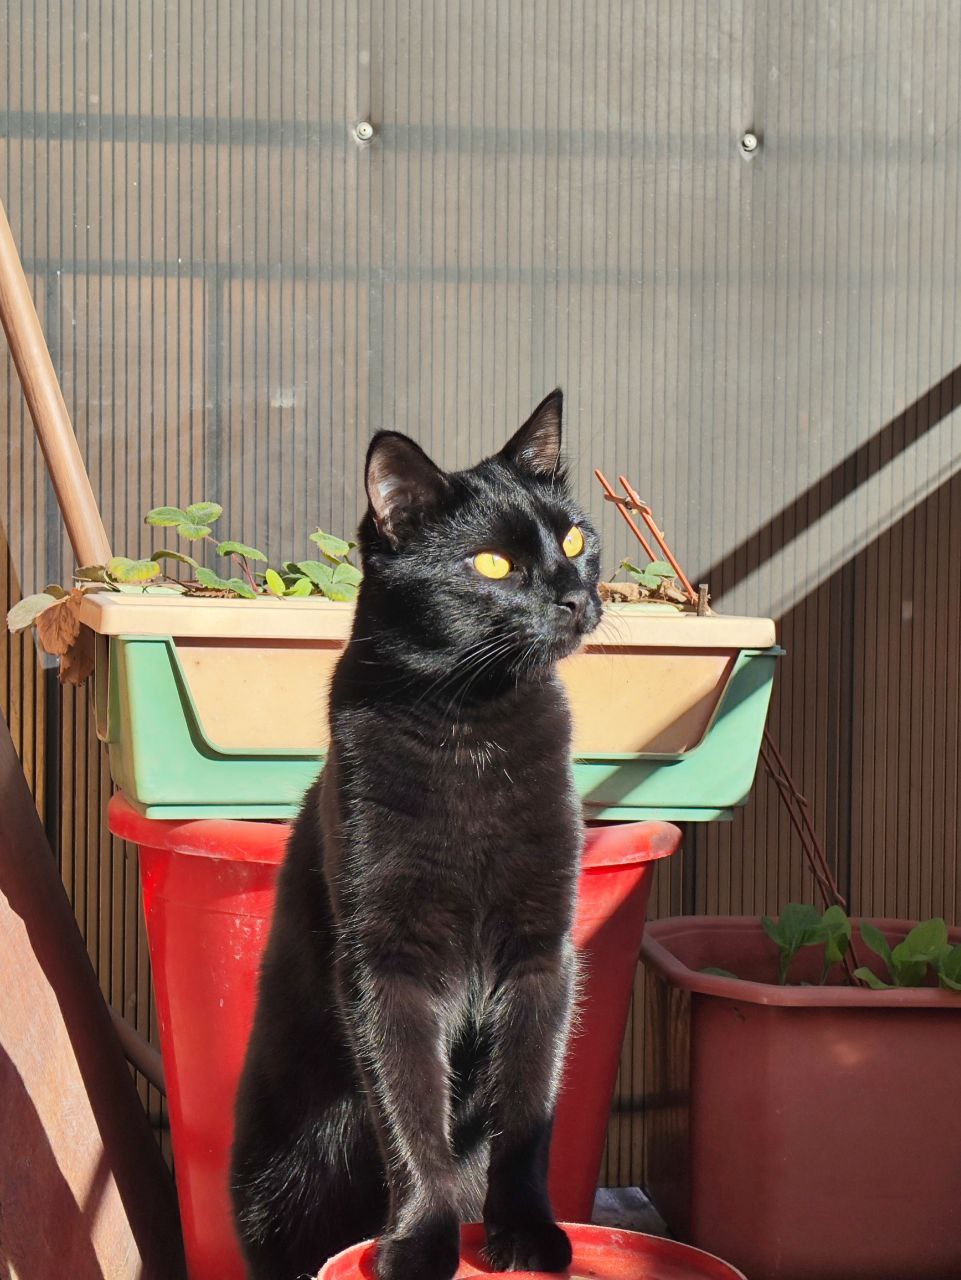

In [44]:
img = Image.open('./imgs/murchik.jpeg')
img 

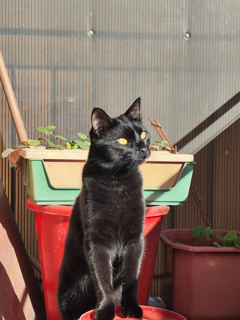

In [45]:
img = img.resize((img.width // 4, img.height // 4))
img

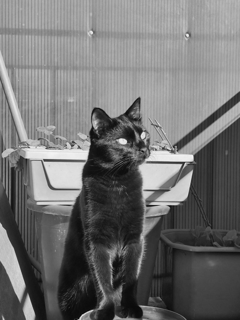

In [46]:
img_l = img.convert('L')
img_l

In [47]:
img_np = np.array(img_l)
img_np.shape

(320, 240)

In [70]:
u, s, vh = np.linalg.svd(img_np, full_matrices=False, compute_uv=True)
u.shape, s.shape, vh.shape

((320, 240), (240,), (240, 240))

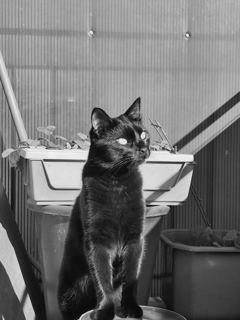

In [101]:
rec = u @ np.diag(s) @ vh
rec_img = Image.fromarray(np.clip(rec).astype(np.uint8))
rec_img

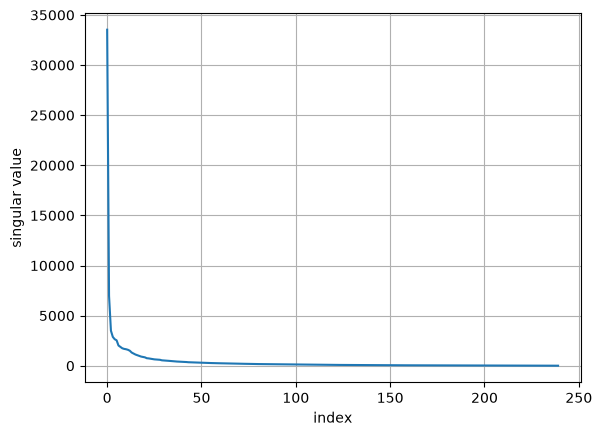

In [102]:
import matplotlib.pyplot as plt 

plt.plot(s)
plt.grid()
plt.xlabel('index')
plt.ylabel('singular value')
plt.show()

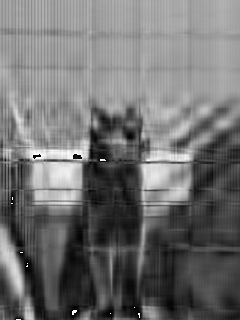

In [92]:
top_k = 10
rec = u[:, :top_k] @ np.diag(s[:top_k]) @ vh[:top_k, :]
rec_img = Image.fromarray(np.clip(rec).astype(np.uint8))
rec_img

In [108]:
h,w = img_np.shape[0], img_np.shape[1]
for k in range(1, len(s) + 1): 
    rec = u[:, :k] @ np.diag(s[:k]) @ vh[:k, :]
    err = np.linalg.norm(img_np - rec, ord='fro') / np.linalg.norm(img_np, ord='fro')  # frobenius norm
    print(f'k {k} storage {k*(h+w+1)} full: {h*w} err: {err}')

k 1 storage 561 full: 76800 err: 0.31285800841425254
k 2 storage 1122 full: 76800 err: 0.24270506548617365
k 3 storage 1683 full: 76800 err: 0.2215871459873525
k 4 storage 2244 full: 76800 err: 0.20607466721945433
k 5 storage 2805 full: 76800 err: 0.19195285011135982
k 6 storage 3366 full: 76800 err: 0.17796910469849347
k 7 storage 3927 full: 76800 err: 0.16851558447886897
k 8 storage 4488 full: 76800 err: 0.15989376598310032
k 9 storage 5049 full: 76800 err: 0.15206508570103391
k 10 storage 5610 full: 76800 err: 0.1444094225971209
k 11 storage 6171 full: 76800 err: 0.13666330570504392
k 12 storage 6732 full: 76800 err: 0.12900342447374044
k 13 storage 7293 full: 76800 err: 0.1218186364845079
k 14 storage 7854 full: 76800 err: 0.11597326800195462
k 15 storage 8415 full: 76800 err: 0.11076439062785363
k 16 storage 8976 full: 76800 err: 0.10614462818756479
k 17 storage 9537 full: 76800 err: 0.10190273217181771
k 18 storage 10098 full: 76800 err: 0.09804548353229772
k 19 storage 10659 ful

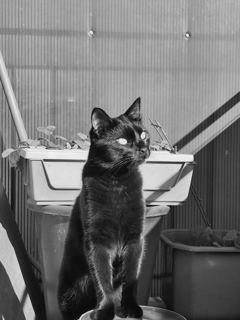

rank:  240

In [119]:
import time
from IPython.display import display

handle = display(None, display_id=True)
for k in range(1, len(s) + 1):
    rec = u[:, :k] @ np.diag(s[:k]) @ vh[:k, :]
    rec_img = Image.fromarray(np.clip(rec).astype(np.uint8))
    print('\rrank: ', k, end='')
    handle.update(rec_img)
    time.sleep(0.2)


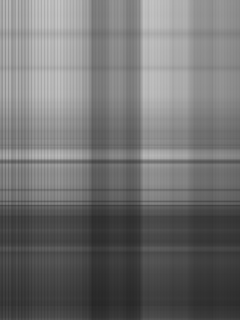

rank:  0

In [124]:
import time
from IPython.display import display

handle = display(None, display_id=True)
for k in range(0, len(s)):
    rec = s[k] * np.outer(u[:, k], vh[k, :])
    rec_img = Image.fromarray(np.clip(rec).astype(np.uint8))
    print('\rrank: ', k, end='')
    handle.update(rec_img)
    time.sleep(0.2)
    break


In [122]:
np.outer?

Signature:       np.outer(a, b, out=None)
Call signature:  np.outer(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function outer at 0x7d381c2423e0>
File:            ~/.local/lib/python3.13/site-packages/numpy/_core/numeric.py
Docstring:      
Compute the outer product of two vectors.

Given two vectors `a` and `b` of length ``M`` and ``N``, respectively,
the outer product [1]_ is::

  [[a_0*b_0  a_0*b_1 ... a_0*b_{N-1} ]
   [a_1*b_0    .
   [ ...          .
   [a_{M-1}*b_0            a_{M-1}*b_{N-1} ]]

Parameters
----------
a : (M,) array_like
    First input vector.  Input is flattened if
    not already 1-dimensional.
b : (N,) array_like
    Second input vector.  Input is flattened if
    not already 1-dimensional.
out : (M, N) ndarray, optional
    A location where the result is stored

Returns
-------
out : (M, N) ndarray
    ``out[i, j] = a[i] * b[j]``

See also
--------
inner
einsum : ``einsum('i,j->ij', a.ravel(), b.ravel())`` is the equivalent.
u